# Build Your Own Call Recogniser

_Integrating Passive Acoustic Monitoring with AI for Scalable Biodiversity Tracking_

## Introduction

Welcome to the agile modelling Python notebook.

### What is a Python notebook?

A Python notebook allows you to run Python code in a Python environment. If you are running this notebook in Google Colab, the Python notebook is running in a virtual machine in the cloud.

### Do I need to be familiar with Python?

No, you do not need to be familiar with Python to work through the notebook. You will interact with the notebook via UI elements such as text boxes, dropdown menus, and buttons.

In fact, most of the Python code in the notebook is hidden by default to allow you to focus on the agile modelling workflow itself. If you are curious to look behind the curtain, you can click a code cell's "Show code" button like so:

<div>
<img src="https://storage.googleapis.com/chirp-public-bucket/esa-2024/reveal_code.png" width="500"/>
</div>

### Notebook overview

In this notebook, we will use a process called "[agile modeling](https://arxiv.org/abs/2302.12948)" to build and incrementally improve a classifier for acoustic analysis, starting from a single classified example. The process uses embeddings provided by the [Perch model](https://www.kaggle.com/models/google/bird-vocalization-classifier). These are the steps we will take:

1. Setup
2. Configure the Perch agile modelling modules
3. Initialise a database of embeddings
4. Search for recordings similar to the annotator-provided example
5. Build a machine learning classifier model from the search results
6. Search your recordings based on the results of the classifier
7. Improve your classifier further using these search results
8. Save your classifier for future use and use it for detection

The agile modelling process is described in more detail in [these slides](https://docs.google.com/presentation/d/e/2PACX-1vTfvoBvCi_V72s0RiIcmFNdnZDcPDCDl-omBbODJ3sz3_IxD5kd1zJjd-J8AR7PE_DgxO-FWDjyP7Mb/pub?start=false&loop=false&delayms=3000&slide=id.g2d63d0c2ccf_0_3915) and in the following diagram:

<div>
<img src="https://storage.googleapis.com/chirp-public-bucket/esa-2024/agile_modelling_workflow.png" width="800"/>
</div>

## 1. Setup

This notebook uses several python "packages".  These have been preinstalled into this environment, but to make use of them in this notebook we need to import them


In [16]:
#@title Install the `perch` package and import requirements
#@markdown <font color='green'>← Run this cell to import the required packages.</font>
#@markdown
#@markdown


import os
import dotenv
from pathlib import Path

from recognizer_workshop.agile_modeling_state import agile_config, agile_state
from recognizer_workshop.agile_modeling_helpers import list_audio_files, labels_from_event_taggings, add_labels_to_db

find_dotenv = dotenv.find_dotenv
load_dotenv = dotenv.load_dotenv


# import numpy as np
# from IPython import display as ipython_display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'



## 2. Configure the Perch agile modelling modules

Here we set some configuration for names and local filepaths and initialize our agile modeling workflow.

In [ ]:

#@markdown The purpose of the `annotator_id` variable below is to keep track of
#@markdown who provided each annotation when collaborating across multiple
#@markdown annotators. This is not strictly necessary for this workhop, but can't hurt.
annotator_id = "phil"  # @param {type:'string'}

# This is the location that this tutorial will use to save data. The "~" your home directory, which 
# you can navigate in the file browser on the left side of the screen.
working_folder = Path('~/my_data')

config = agile_config(
    db_path=working_folder / 'db', # path to the pre-generated SQLite database of embeddings
    annotator_id=annotator_id,
    search_dataset_name="search_set",
    embeddings_folder=None, # not required anymore
    labeled_examples_folder=working_folder / 'labeled_examples',
    models_folder=working_folder / 'models',
    predictions_folder=working_folder / 'predictions',
)

Path(config.labeled_examples_folder).mkdir(exist_ok=True, parents=True)

config.baw_config['domain'] = 'api.ecosounds.org'

agile = agile_state(config)

## Configure access to your Ecosounds project

We will be loading audio from [Ecosounds](https://www.ecosounds.org), an online repository of ecoacoustic recordings. If working with a
private Ecosounds project, we need to provide the Ecosounds *auth token* associated with your ecosounds account.

To find your ecosounds token, go to https://www.ecosounds.org/my_account and in the bottom left, click on the button to copy the token like so:

 <div><img src="https://storage.googleapis.com/chirp-public-bucket/esa-2024/ecosounds_token.png" width="800"/></div>

Because this is a secret, we should avoid saving it in plain text in the notebook, so we will set it up in an environment variable.

1. In the working directory create a file named `.env`
    - If you are not sure where your working directory is, run the cell below and it should create it for you. 
2. In this .env file, put the line `BAW_AUTH_TOKEN=abc123xyz` (replace `abc123xyz` with the token you copied from Ecosounds)

In [ ]:

# this should automatically prompt for the token and create the .env file
agile.init_workbench()


Updating BAW API token...

Authentication token is missing or invalid.
Found .env file: /Users/eichinsp/Documents/github/peichins/recognizer-workshop/.env

Setting Authorization header for the BAW API...
Token set to: R_r***xi0
Request was successful!

--- REQUEST/RESPONSE DEBUG INFO ---
--- CONTEXT: Debug mode is active (successful request) ---

--- DETAILS OF THE REQUEST SENT ---
Method: GET
URL:    https://api.ecosounds.org/status

Headers Sent:
  User-Agent: python-requests/2.32.3
  Accept-Encoding: gzip, deflate, zstd
  Accept: */*
  Connection: keep-alive
  Authorization: Token token="R_raqN0FbMczwsICm3XnDkzm1v-p0g2v6rtn0aXnxi0"
  Content-Type: application/json

Body/Payload Sent:
No body was sent.

--- DETAILS OF THE SERVER'S RESPONSE ---
Status Code: 200
Response Headers:
  Server: nginx
  Date: Sun, 15 Jun 2025 13:03:58 GMT
  Content-Type: application/json; charset=utf-8
  Transfer-Encoding: chunked
  Connection: keep-alive
  Status: 200 OK
  vary: Origin
  x-request-id: 5acd

## 3. Initalize a database of embeddings

In [19]:
#@title Initialize the agile modelling workflow and database of embeddings
#@markdown <font color='green'>← Run this cell to initialize the workflow.

agile.initialize()

Initializing DB...
DB Summary:
Number of embeddings: 720575
1 Dataset(s):
search_set
Label counts:
Yellow-bellied glider: 14 positive, 1 negative


In [20]:
#@title Inspect and annotate the search results
#@markdown <font color='green'>← Run this cell after reading the instructions
#@markdown below to inspect and annotate the retrieved recordings in the
#@markdown database.</font>
#@markdown
#@markdown We are now ready to look at our first search results. For each
#@markdown example you can look at a spectrogram and listen to the audio, then
#@markdown apply a positive label if it is a positive match or a negative label
#@markdown if it's not a match.
#@markdown
#@markdown The label itself that will be applied is any string you specify via
#@markdown the text form below and is up to you. For instance, you could apply
#@markdown the `ybg` label for yellow-bellied glider vocalizations.
query_label = 'Yellow-bellied Glider'  #@param {type:'string'}
#@markdown Click the label below each recording to annotate it: click once to
#@markdown turn it green (positive label), twice to turn it orange (negative
#@markdown label), or leave it unclicked (or click a third times to reset) if
#@markdown you don't want to apply any label to the recording (i.e., you don't
#@markdown want to add it to your labelled training set at all).
#@markdown
#@markdown > **NOTE: loading the spectrograms can sometimes fail. If you see
#@markdown > some examples that failed to load, try running the cell a second
#@markdown > time before starting your labelling.**

agile.show_label_selector(query_label)

TypeError: agile_state.show_label_selector() takes 1 positional argument but 2 were given

### What is an embedding?

Think of an embedding as a summary of the audio waveform in the form of an array of numbers. In the context of deep learning (which Perch relies on), that array of numbers is obtained by passing a _spectrogram_ representation of the audio through a deep neural network.

<div>
<img src="https://storage.googleapis.com/chirp-public-bucket/esa-2024/what_is_an_embedding.png" width="800"/>
</div>

The exact details can be safely ignored for the purpose of this tutorial, but the neural network was constructed and trained in such a way that the relationship between the embeddings it outputs tend to be consistent with the semantic relationships between the audio waveforms (e.g., passing two different vocalizations for the same animal species through the neural network will produce similar embeddings).

We will exploit this property in our agile modelling workflow.

The first step in the workflow is therefore to compute an embedding with Perch for every 5-second audio clip extracted from our audio recordings. In the interest of time, those embeddings have already been computed and assembled into a database.


### Add labels to the database

We will grab all the annotations from the ecosounds recordings in your search set and add them to the database so they can be used as labeled examples for training. 

In [ ]:
region_id = 85  # @param {type: 'number'}

labels = labels_from_event_taggings(agile.baw_api, filter_params={"region_id": [region_id]})
add_labels_to_db(agile, config, labels)

Request was successful!

--- REQUEST/RESPONSE DEBUG INFO ---
--- CONTEXT: Debug mode is active (successful request) ---

--- DETAILS OF THE REQUEST SENT ---
Method: POST
URL:    https://api.ecosounds.org/sites/filter?disable_paging=true

Headers Sent:
  User-Agent: python-requests/2.32.3
  Accept-Encoding: gzip, deflate, zstd
  Accept: */*
  Connection: keep-alive
  Authorization: Token token="R_raqN0FbMczwsICm3XnDkzm1v-p0g2v6rtn0aXnxi0"
  Content-Type: application/json
  Cookie: XSRF-TOKEN=eEm-Ex5KaCM6BFKVwdCIMZOWinggkFGSAPD_qRlNn7U-KsJpo6vVSYzw1XwiJxpjixzrGBBjEQlVLEB-MMtlTQ; _baw_session=4A7DTA1I81cxzkZNONSBITQeCBm%2BEtJyYtmTOvT7TvxyIUDOq5G7bmLTA1lXtj%2B%2B32aA5TDIzSdp2p%2FWEO9xQImFLb2O9AyhL12lHws7MK8bCfKo5IZB%2F5eYYthHJyBvX0eCZxXKCJDAK1DgwCFnzaMJ6RCAmEkDujTMTVTlQrVOMMrjtftNVAPoBrRL4uPGfdh2JZPOP3lOyORomZ7Lm6xMSd2H23NyLr%2FOdocsg3NeUIfPUbjPWFCOBxOvXOMGifPhnJume8d2VcRnnLlOwG1%2BgeD%2FaT3pgaF%2FUolhJ1z%2FOUDEv0Kadr7bDybNaKOzVqMtjgk4McRbYvnvPwb3QUUlnhPJRlBLjwSZAlm9JGOiEkBEQsAx5SfZSLjldCn

## 4. Search for recordings similar to the annotator-provided example

Here, we take a single example and find the examples in our search set which most closely match that example. This is a way to get started with a labelled training set.

You have a few options to provide examples.

### A. Upload some short clips

In [ ]:
#@title A. Copying your own files in Google Drive
#@markdown <font color='orange'>← [OPTIONAL] Run this cell to list audio files
#@markdown in your mounted Google Drive folder.</font>
#@markdown
#@markdown If you have short examples of your target call, copy them into the
#@markdown `config.labeled_examples_folder` directory and then run this cell to
#@markdown check that they are accessible.
#@markdown
#@markdown If you are unsure where that is, running this cell will display the
#@markdown path to `config.labeled_examples_folder`.

audio_files = list_audio_files(config.labeled_examples_folder)

Found 4 audio files in /Users/eichinsp/Documents/github/peichins/recognizer-workshop/local_scripts/test_folder/labeled_examples
0: /Users/eichinsp/Documents/github/peichins/recognizer-workshop/local_scripts/test_folder/labeled_examples/2023_point_23a_4483_2487624_20230227_110451_11_0.wav
1: /Users/eichinsp/Documents/github/peichins/recognizer-workshop/local_scripts/test_folder/labeled_examples/conondale_point_location_13_4404_2443188_20220821_125509_5_0.wav
2: /Users/eichinsp/Documents/github/peichins/recognizer-workshop/local_scripts/test_folder/labeled_examples/conservation_ecology_centre_649_232859_20120728_101842_5_0.wav
3: /Users/eichinsp/Documents/github/peichins/recognizer-workshop/local_scripts/test_folder/labeled_examples/conondale_point_location_13_4404_2443188_20220821_125439_6_0.wav


### B. Provide a URL or Xeno Canto ID

You can also directly provide a URL pointing to the example or a Xeno-Canto ID in the form `xc123456`.

In [ ]:
#@title Load the query audio { vertical-output: true }
#@markdown <font color='green'>← Run this cell after reading the instructions
#@markdown below to load the query audio.</font>
#@markdown
#@markdown The `query` below can be
#@markdown 1. one of the integer indices listed after running the cell for
#@markdown    option A above; or
#@markdown 2. a URL, filepath, or Xeno-Canto ID (in the form `xc123456`).
query = '2' # @param {type:'string'}
#@markdown Running the cell will display the example and allow you to select the
#@markdown 5-second portion of it to use.
#@markdown > **NOTE: If your example is too long, this can make the selection of
#@markdown > the 5-second segment a bit more difficult.**

agile.display_query(query)

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='offset_s', max=5.0), Output…

I0000 00:00:1749989609.846611 15062069 service.cc:152] XLA service 0x3cb5de600 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1749989609.846630 15062069 service.cc:160]   StreamExecutor device (0): Host, Default Version
I0000 00:00:1749989610.807088 15062069 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


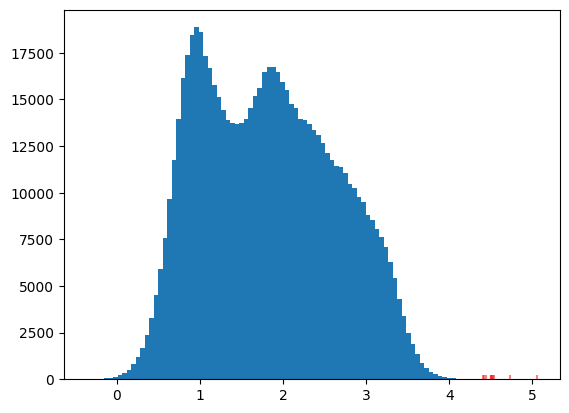

In [ ]:
#@title Embed the query and retrieve most similar candidates
#@markdown <font color='green'>← Run this cell after reading the instructions
#@markdown below to embed the query and perform the search.</font>
#@markdown
#@markdown The next step is to generate an embedding for the 5-second example
#@markdown and then compare it against the embeddings in the database to find
#@markdown the most similar 5-second clips from your search dataset.
#@markdown
#@markdown > **NOTE: You can leave the options below unchanged when first running
#@markdown > this cell.**
#@markdown
#@markdown The `num_results` parameter controls the number of search results to
#@markdown present. Larger numbers allow to annotate more search results at a time,
#@markdown but going through the results requires more annotator time.
num_results = 10  #@param
#@markdown When leaving `target_score` to None, the clips being surfaced will be
#@markdown the top `num_results` most similar clips with respect to the provided
#@markdown query example.
target_score = None  #@param
#@markdown It can however be useful to retrieve embeddings with different levels
#@markdown of similarity, for instance to get good "negative" training examples
#@markdown to contrast against the "positive" matches. Running this cell will
#@markdown display a histogram of scores like this one:
#@markdown
#@markdown <div><img src="https://storage.googleapis.com/chirp-public-bucket/esa-2024/logits_distribution.png" width="300"/></div>
#@markdown
#@markdown The x-axis represents some arbitrary similarity "score", and the y-axis
#@markdown represents how many embeddings in the database share that score. In
#@markdown the example above, a `target_score` of 0.0 would for instance retrieve
#@markdown embeddings in the database whose similarity "score" is closest to 0.0
#@markdown and which are therefore amongst the most dissimilar to the provided
#@markdown example.

agile.embed_query()

agile.search_with_query(
    num_results=num_results,
    # When working with really large datasets it may be necessary for
    # performance reasons to look at a smaller (random) subset of the database
    # entries to perform the search. Replacing None with an integer argument
    # would limit the search to a random subset of that size.
    sample_size=None,
    target_score=target_score,
)

In [ ]:
agile.display_search_results()

No label set. Please select a label before displaying search results.


In [ ]:
#@title Save the annotations { vertical-output: true }
#@markdown <font color='green'>← Run this cell to save your annotations.</file>
#@markdown
#@markdown This will save the newly labelled examples to the database.

agile.save_labels()

AttributeError: 'NoneType' object has no attribute 'harvest_labels'

Repeat the above cycle with a few different audio queries:

1. Load the query audio.
2. Embed the query and retrieve most similar candidates.
3. Inspect and annotate the search results.
4. Save the annotations.

If your target species has multiple call types, it would be a good idea to search for at least one of each call type.

## 5. Build a machine learning classifier model from the search results

Now that we have labelled a number of our embedded audio clips in the search set, we have what we need to train and evaluate a classifier.

At a high level, you can think of our embeddings as points on a map. From that perspective, classifying audio clips as "positive" (match) or "negative" (not a match) can be thought of as figuring out "territories" on our map for positives and negatives. If an embedding for a particular audio clip falls into the "positives" territory, it is classified as a positive, and vice versa.

<div>
<img src="https://storage.googleapis.com/chirp-public-bucket/esa-2024/classification.png" width="800"/>
</div>

To continue with the analogy, our territories are defined using "capital cities": we place a capital city for positives and one for for negatives on our map, and the territory that any point on our map belongs to is determined by which capital city the point is closest to.

"Training" the classifier therefore reduces to finding the two points on our map at which to place the capital cities such that the territories they claim align with our labelled audio clips. In an ideal case, the capitals should be located such that all positively-labelled clips in our dataset are in the "positives" territory, and vice versa.

The process by which we figure out the locations of our capital cities is beyond the scope of this tutorial, and the knobs one needs to tune to control the behavior of that process can be safely ignored and left to their default settings below. Refer to the short explanation under each parameter for more details.

In [ ]:
#@title Train the classifier { vertical-output: true }
#@markdown <font color='green'>← Run this cell to train the classifier.</file>
#@markdown
#@markdown The `target_labels` parameter controls the set of labels to classify.
#@markdown If None, auto-populated from the database. If you have put more than
#@markdown one class into your embeddings database, and you don't want to build
#@markdown the model to include all of these, list the ones you do want to include.
target_labels = None  #@param
#@markdown *The following impact the procedure by which the "capital city locations"
#@markdown are computed. This is an iterative procedure.*
#@markdown
#@markdown How much to update the locations at each step.
learning_rate = 1e-3  #@param
#@markdown How many steps to do:
num_steps = 101  #@param
#@markdown How many labelled examples to use at each step to determine an update
#@markdown direction.
batch_size = 32  #@param
#@markdown *The following are to do with the labelled data inputs:*
#@markdown
#@markdown A random subset of the labelled audio is not used to train the model,
#@markdown but instead is used to test the model. This is so we know roughly how
#@markdown well the model does on classifying examples that it has never seen before.
train_ratio = 0.9  #@param
#@markdown In your database we have a lot of audio, most of which is probably
#@markdown not your target. By taking some random clips from your unlabelled
#@markdown audio and treating them as negative examples, we can train on a wider
#@markdown variety of negative examples than what has been explicitly labelled
#@markdown as negative. However, because we don't know for sure that this process
#@markdown didn't choose a positive example by chance, we give each one less
#@markdown importance in the training.
weak_neg_weight = 0.05  #@param
#@markdown How many of these randomly chosen examples to include for each batch
#@markdown (on top of the number in the strongly labelled batch).
weak_negatives_batch_size = 16  #@param

agile.train_classifier(target_labels, learning_rate, weak_neg_weight, num_steps, train_ratio, batch_size, weak_negatives_batch_size)


Training for target labels : 
('Yellow-bellied glider',)


Loss 0.05566368:  99%|█████████▉| 100/101 [00:00<00:00, 138.44it/s]



--------------------------------------------------------------------------------
top-1      1.000
roc_auc    1.000
cmap       nan


/Users/eichinsp/miniconda3/envs/recognizer-workshop/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/eichinsp/miniconda3/envs/recognizer-workshop/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


## 6. Search your recordings based on the results of the classifier

Now that we have a trained classifier, we can follow the same process as for the single example query. We search the database for more examples using the classifier, label them, then re-train the classifier with the new examples.

The classifier outputs a score for each example in the search set. Large positive/negative values mean the classifier predicts a positive/negative label with strong confidence, whereas values around zero mean the classifier's confidence is low.

When searching using the classifier, we can look for examples with the highest score by setting `target_score` to `None`.  This might get us more positive examples but these probably won't improve the classifier much, because they already have a high score. More useful is to search for those examples that the classifier is least sure about, by setting `target_score` to `0`.  Try setting the target score to None, 0 and possibly some other values depending on how many positive examples come back from each of those.

target_labels:  ('Yellow-bellied glider',)


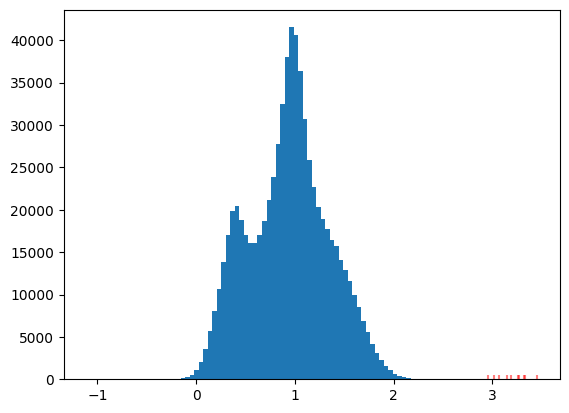

In [ ]:
#@title Search the database using the classifier { vertical-output: true }
#@markdown <font color='green'>← Run this cell to search the database using the classifier.</file>
#@markdown
#@markdown Refer to the _Embed the query and retrieve most similar candidates_
#@markdown and _Inspect and annotate the search results_ steps for more
#@markdown information on the parameters below.
num_results = 10  #@param
target_score = None  #@param

agile.search_with_classifier(
    num_results=num_results,
    # When working with really large datasets it may be necessary for
    # performance reasons to look at a smaller (random) subset of the database
    # entries to perform the search. Replacing None with an integer argument
    # would limit the search to a random subset of that size.
    sample_size=None,
    target_score=target_score,
)

Page 1 of 2
--------------------------------------------------------------------------------



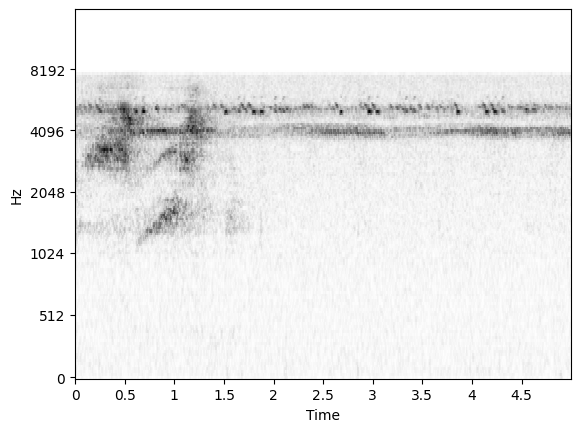

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487323/original
offset_s     : 1180.00
score        : 3.45


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------


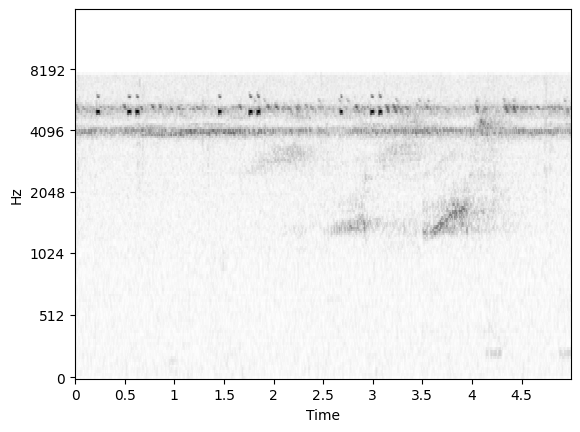

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487323/original
offset_s     : 240.00
rank         : 1
score        : 3.33


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------


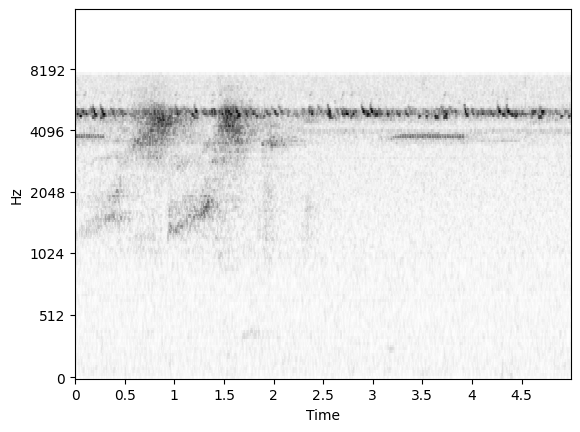

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487376/original
offset_s     : 1170.00
rank         : 2
score        : 3.32


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------


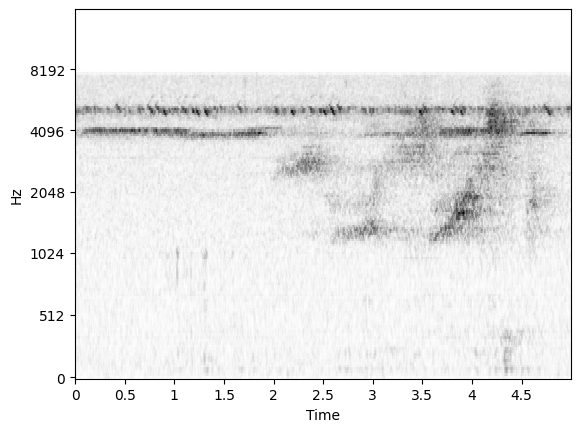

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487323/original
offset_s     : 3015.00
rank         : 3
score        : 3.27


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------


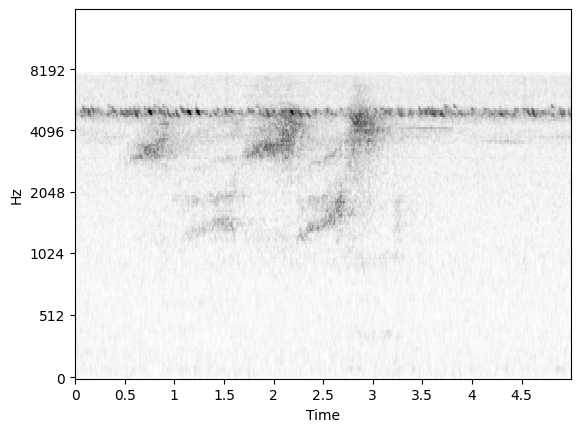

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487376/original
offset_s     : 1045.00
rank         : 4
score        : 3.26


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------


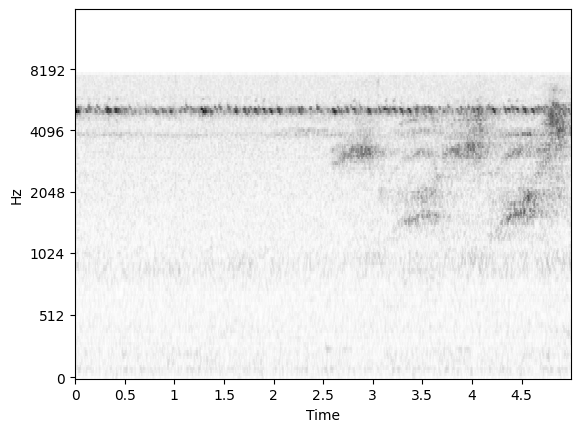

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487367/original
offset_s     : 1535.00
rank         : 5
score        : 3.19


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------


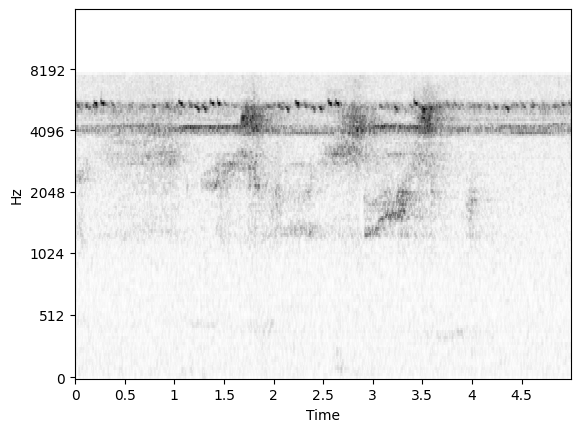

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487624/original
offset_s     : 2080.00
rank         : 6
score        : 3.15


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------


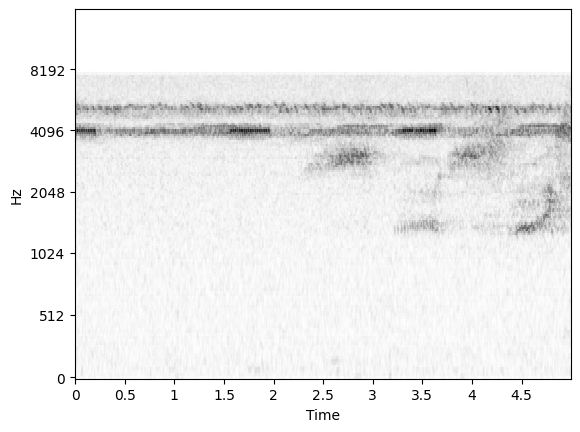

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487323/original
offset_s     : 335.00
rank         : 7
score        : 3.07


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------
No audio loaded for https://api.ecosounds.org/audio_recordings/2487376/original :: 2315.0.

--------------------------------------------------------------------------------


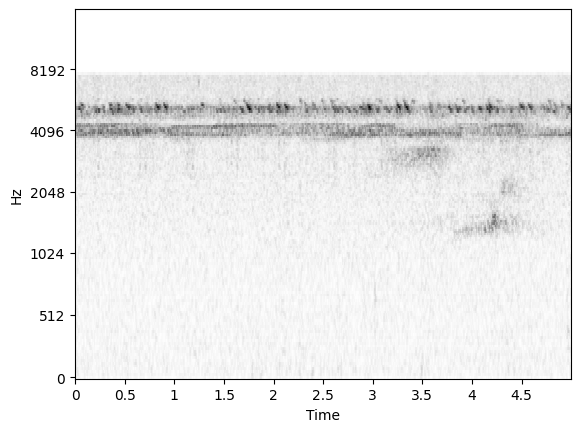

dataset name : search_set
source uri   : https://api.ecosounds.org/audio_recordings/2487323/original
offset_s     : 350.00
rank         : 9
score        : 2.96


GridspecLayout(children=(Button(description='Yellow-bellied glider', layout=Layout(grid_area='widget001'), sty…


--------------------------------------------------------------------------------
Page 1 of 2


Button(description='Prev Page', style=ButtonStyle())

Button(description='Next Page', style=ButtonStyle())

In [ ]:
#@title Inspect and annotate the search results
#@markdown <font color='green'>← Run this cell to inspect and annotate the
#@markdown retrieved recordings in the database.</font>
agile.display_search_results()


In [ ]:
#@title Save the annotations { vertical-output: true }
#@markdown <font color='green'>← Run this cell to save your annotations.</file>
agile.save_labels()


new_lbls:  2

prev_lbls:  7
Label counts:
Yellow-bellied glider: 14 positive, 1 negative


(7, 2)

## 7. Improve your classifier further using these search results

You can now go back to the _Build a machine learning classifier model_ section to retrain the classifier based on all annotations provided so far.

## Saving your classifier and running inference

The trained classifier consists of the following elements
1. The *weights* of the model (how to multiply and add the embedding values together to produce higher scores for the examples of the target class than other examples), which were learned during training.
2. The model *bias* (how to shift the scores so that scores for positive examples are positive and vice-versa), also learned during training.
3. The list of labels (class names) corresponding to the output scores
4. Some metadata related to the model that created the embeddings, so that if the classifier is used on new audio, we make sure to embed in a compatible way.

With this information, the classifier can be saved and used on other search sets later on.

## 8. Save your classifier for future use and use it for detection

In [ ]:
#@title Save your classifier for future use
#@markdown <font color='green'>← Run this cell to save your classifier.</file>
classifier_name = 'ybg_01'  #@param {type:'string'}

classifier_path = config.models_folder / f'{classifier_name}.json'

classifier_path.parent.mkdir(exist_ok=True, parents=True)

agile.classifier.save(classifier_path)

We can also use the model to perform detection over all of the search dataset and save the results to a CSV file.

run the model over all of the search dataset and save the results to a csv. Specify:
1. The csv filename to save the results to
2. The threshold. Anything above the threshold for the target labels will be saved. Typically this would be zero to save anything the classifier believes is the target class
3. Which labels to include. Leave it as None to include all the labels you trained for.

In [ ]:
#@title Perform detection on the search set
#@markdown <font color='green'>← Run this cell to perform detection on the search set.</file>
#@markdown
#@markdown This specifies the CSV filename to save the results to.
output_filename = 'ybg_output.csv'  #@param {type:'string'}
#@markdown The `threshold` determines what constitutes a detection. The classifier
#@markdown outputs a score for every embedding in the search set; anything above
#@markdown the threshold is considered a detection. A higher threshold value
#@markdown results in fewer but more confident detections, at the cost of missing
#@markdown out on relevant events in the search set. Conversely, a lower threshold
#@markdown value results in more but less confident detections, at the cost of
#@markdown producing more false positive detections.
threshold = 1.0 # @param {"type":"number"}
#@markdown You can also specify a random subset of the dataset to run inference
#@markdown on, e.g. 0.5 for 50%.
subset = 0.1 #@param {type:'string'}

# Which labels to include in the output file. If None, all labels are included.
labels = None

output_filepath = config.predictions_folder / output_filename
output_filepath.parent.mkdir(parents=True, exist_ok=True)
agile.run_inference(
    output_filepath,
    threshold=threshold,
    dataset=config.search_dataset_name,
    subset=subset,
)